# 01 · EDA: HMDA mortgage applications, nationwide (2024–2025)

**Task:** predict whether a mortgage application is **denied** (`action_taken = 3`) vs approved (`1`, `2`).

Data: FFIEC HMDA public loan-level (LAR) snapshot, all states, 2024 and 2025, action codes 1–5
(~22.5M rows). Run `python -m hmda.data` once to build `data/processed/hmda_2024_2025.parquet`
(see README).

* Exact nationwide aggregates are computed in **DuckDB** over the full data (seconds).
* Model-based feature importance (section 9) uses a reproducible **sample**.

Sections: 1 overview · 2 geography · 3 loan characteristics · 4 borrower financials ·
5 credit & underwriting · 6 lenders · 7 missingness & leakage · 8 protected attributes ·
9 feature importance · 10 takeaways

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from hmda.data import connect, load_hmda, approved_vs_denied
from hmda.features import (DTI_MAP, LEAKAGE_COLS, PROTECTED_COLS, HMDAFeatures,
                           make_pipeline, split_xy)
from hmda import plotting as hp

hp.use_style()
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.3f}".format)

con = connect()
# `apps` = decided applications (approved or denied) with a 0/1 denied flag
con.sql("""
    CREATE OR REPLACE VIEW apps AS
    SELECT *, (action_taken = '3')::INT AS denied
    FROM hmda WHERE action_taken IN ('1', '2', '3')
""")

def rate_by(expr, where="TRUE", view="apps", min_n=0):
    """Denial rate and count grouped by a SQL expression, over the full data."""
    return con.sql(f"""
        SELECT {expr} AS value, count(*) AS n, avg(denied) AS denial_rate
        FROM {view} WHERE {where} GROUP BY 1 HAVING count(*) >= {min_n} ORDER BY n DESC
    """).df()

OVERALL = con.sql("SELECT avg(denied) FROM apps").fetchall()[0][0]
print(f"overall denial rate (approved vs denied, nationwide): {OVERALL:.3f}")

overall denial rate (approved vs denied, nationwide): 0.234


## 1. Overview

In [2]:
outcome = con.sql("""
    SELECT activity_year AS year,
           CASE action_taken WHEN '1' THEN 'approved' WHEN '2' THEN 'approved'
                WHEN '3' THEN 'denied' WHEN '4' THEN 'withdrawn' ELSE 'incomplete' END AS outcome,
           count(*) AS n
    FROM hmda GROUP BY ALL
""").df().pivot(index="outcome", columns="year", values="n")
outcome["total"] = outcome.sum(axis=1)
outcome.loc["all"] = outcome.sum()
display(outcome.style.format("{:,.0f}"))

by_year = rate_by("activity_year").sort_values("value")
display(by_year)

year,2024,2025,total
outcome,,,
approved,"6,536,612","7,245,852","13,782,464"
denied,"2,099,966","2,115,090","4,215,056"
incomplete,"581,629","695,006","1,276,635"
withdrawn,"1,536,699","1,710,723","3,247,422"
all,"10,754,906","11,766,671","22,521,577"


,value,n,denial_rate
1,2024,8636578,0.243
0,2025,9360942,0.226


About 18M decided applications; ~23% are denied. Withdrawn and incomplete applications (~4.5M)
are excluded from the main task because they have no lender decision.

## 2. Geography

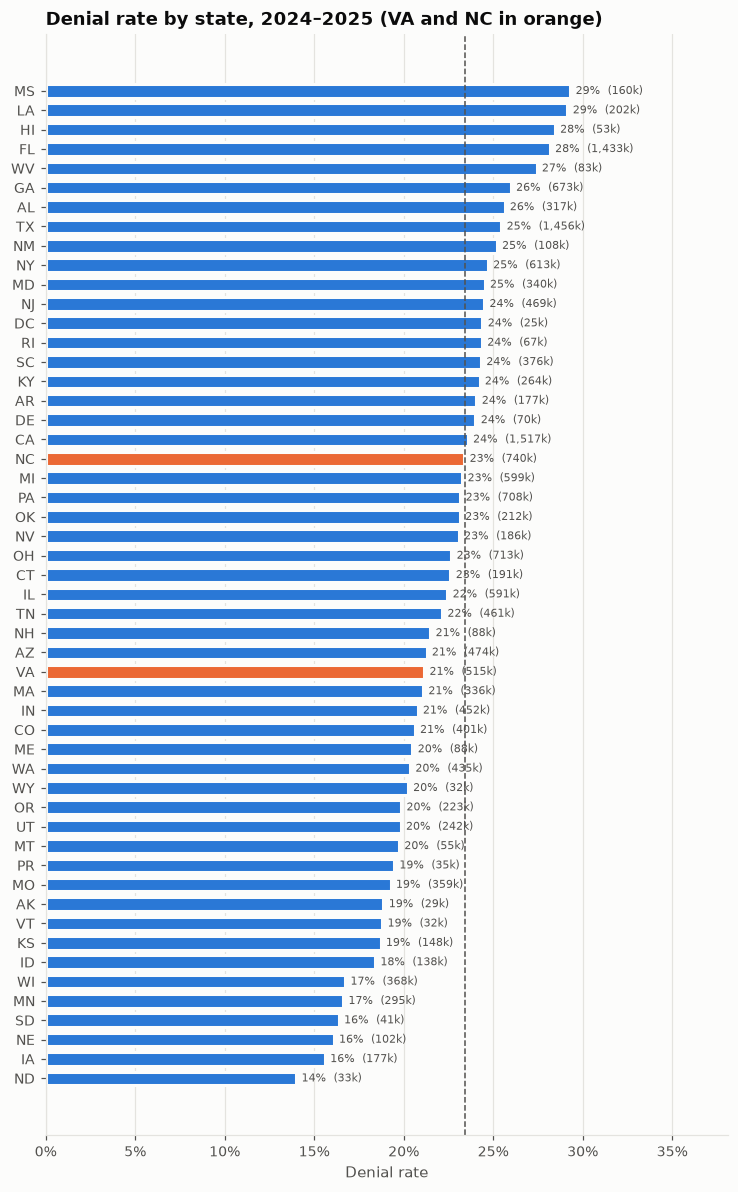

In [3]:
states = rate_by("state_code", min_n=1000).dropna().sort_values("denial_rate", ascending=False)

fig, ax = plt.subplots(figsize=(8, 13))
colors = [hp.ORANGE if s in ("VA", "NC") else hp.BLUE for s in states["value"]]
ax.barh(range(len(states)), states["denial_rate"], color=colors, height=0.7,
        edgecolor=hp.SURFACE, linewidth=2)
ax.set_yticks(range(len(states)), states["value"])
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.axvline(OVERALL, color=hp.TEXT_SECONDARY, lw=1, ls="--")
for i, (r, n) in enumerate(zip(states["denial_rate"], states["n"])):
    ax.text(r + 0.003, i, f"{r:.0%}  ({n/1e3:,.0f}k)", va="center", fontsize=7.5, color=hp.TEXT_SECONDARY)
ax.set(title="Denial rate by state, 2024–2025 (VA and NC in orange)", xlabel="Denial rate")
ax.set_xlim(0, states["denial_rate"].max() * 1.3)
plt.show()

In [4]:
state_year = con.sql("""
    SELECT state_code, activity_year, avg(denied) AS rate, count(*) AS n
    FROM apps WHERE state_code IS NOT NULL GROUP BY ALL
""").df().pivot(index="state_code", columns="activity_year", values="rate")
state_year["change_pp"] = (state_year["2025"] - state_year["2024"]) * 100
print("national 2024 -> 2025:", by_year.set_index("value")["denial_rate"].round(3).to_dict())
print("states where denial rate fell:", (state_year["change_pp"] < 0).sum(), "of", len(state_year))
display(state_year.sort_values("change_pp").iloc[[0, 1, 2, -3, -2, -1]])
display(state_year.loc[["VA", "NC"]])

national 2024 -> 2025: {'2024': 0.243, '2025': 0.226}
states where denial rate fell: 54 of 54


activity_year,2024,2025,change_pp
state_code,,,
VI,0.178,0.081,-9.670
NJ,0.261,0.231,-3.019
DE,0.254,0.227,-2.661
ND,0.143,0.137,-0.570
MN,0.169,0.163,-0.564
OK,0.234,0.229,-0.558


activity_year,2024,2025,change_pp
state_code,,,
VA,0.221,0.203,-1.868
NC,0.240,0.228,-1.181


State denial rates range about 2x, from ~14–17% in the Upper Midwest (ND, IA, NE, SD, MN, WI) to
~27–29% in MS, LA, HI, FL, and WV. VA (21%) and NC (23%) are at or slightly below the national 23%.
Denial rates fell from 2024 to 2025 in every state shown (national 24.3% → 22.6%).
In section 9, `state_code` adds little once financials and lender are known.

## 3. Loan characteristics

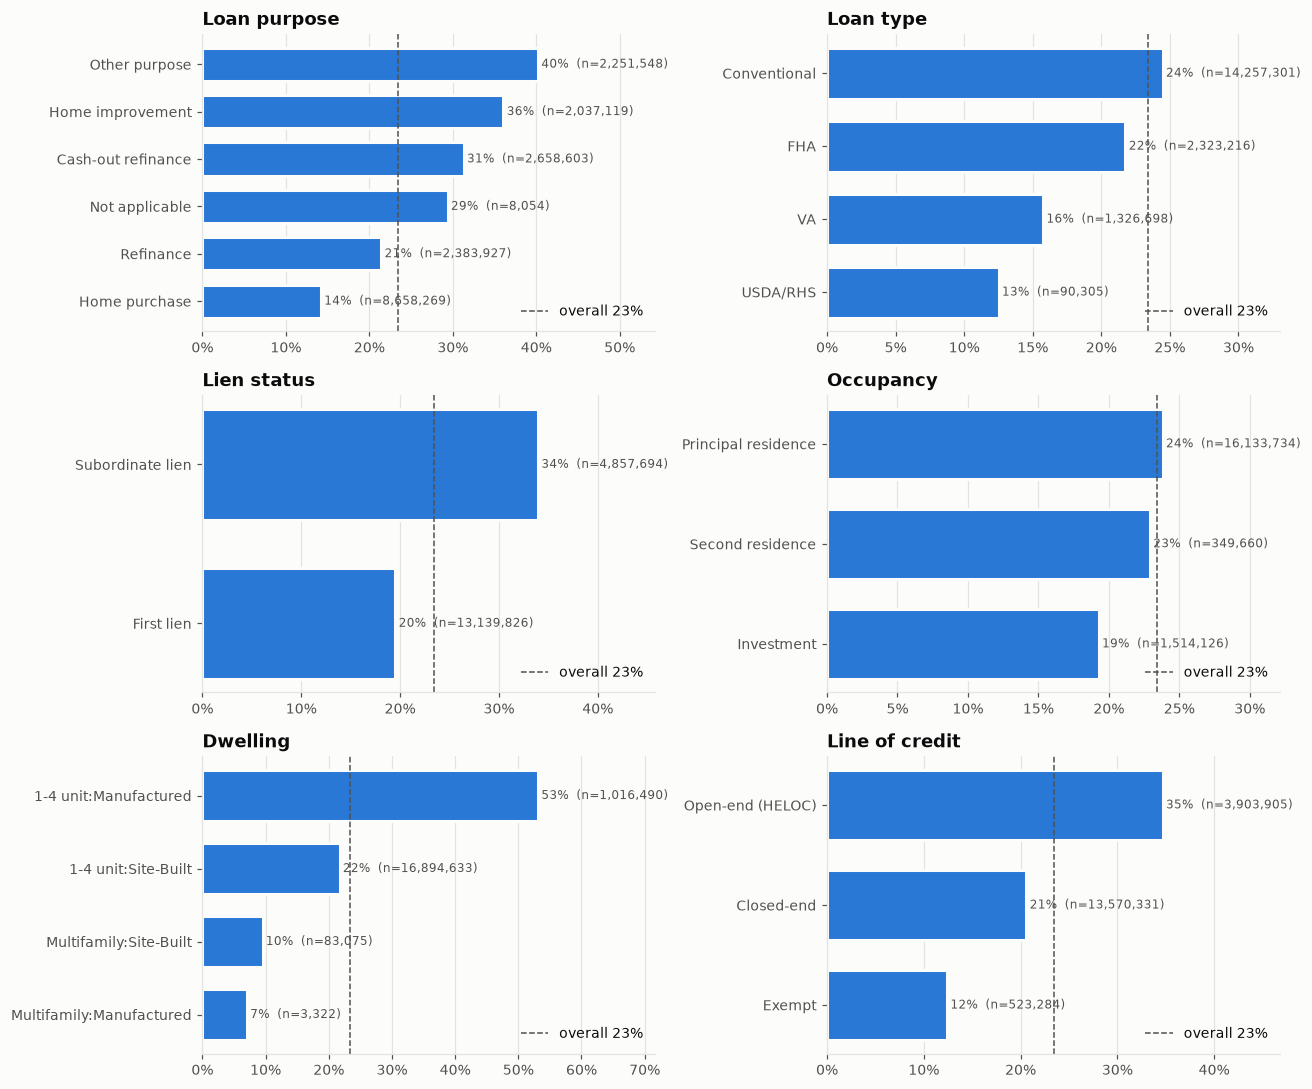

In [5]:
purpose_map = {"1": "Home purchase", "2": "Home improvement", "31": "Refinance",
               "32": "Cash-out refinance", "4": "Other purpose", "5": "Not applicable"}
loan_type_map = {"1": "Conventional", "2": "FHA", "3": "VA", "4": "USDA/RHS"}
lien_map = {"1": "First lien", "2": "Subordinate lien"}
occ_map = {"1": "Principal residence", "2": "Second residence", "3": "Investment"}

panels = [
    ("loan_purpose", purpose_map, "Loan purpose"),
    ("loan_type", loan_type_map, "Loan type"),
    ("lien_status", lien_map, "Lien status"),
    ("occupancy_type", occ_map, "Occupancy"),
    ("derived_dwelling_category", None, "Dwelling"),
    ("open_end_line_of_credit", {"1": "Open-end (HELOC)", "2": "Closed-end", "1111": "Exempt"}, "Line of credit"),
]
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for ax, (col, mapping, title) in zip(axes.flat, panels):
    d = rate_by(col, min_n=1000).sort_values("denial_rate", ascending=False)
    labels = d["value"].map(mapping) if mapping else d["value"].str.replace("Single Family (1-4 Units)", "1-4 unit")
    hp.rate_barh(ax, labels.fillna(d["value"]).tolist(), d["denial_rate"].tolist(), d["n"].tolist(),
                 overall=OVERALL, title=title, xlabel="")
fig.tight_layout(); plt.show()

* **Home purchase loans are denied least (~14%)**; home improvement, "other", and cash-out refis are
  denied 30–40%. Subordinate liens (mostly HELOCs/second mortgages) are denied far more than first liens.
* **Manufactured homes are denied over half the time**, more than double site-built homes.
* The product mix differs a lot, so the original VA/NC "core" scope (home purchase, first lien,
  owner-occupied) is a much easier slice than the whole market:

In [6]:
core = "loan_purpose = '1' AND lien_status = '1' AND occupancy_type = '1'"
core_stats = con.sql(f"""
    SELECT ({core}) AS core_scope, count(*) AS n, avg(denied) AS denial_rate
    FROM apps GROUP BY 1 ORDER BY 1 DESC
""").df()
core_stats["share"] = core_stats["n"] / core_stats["n"].sum()
core_stats

,core_scope,n,denial_rate,share
0,True,7277822,0.143,0.404
1,False,10719698,0.296,0.596


## 4. Borrower financials

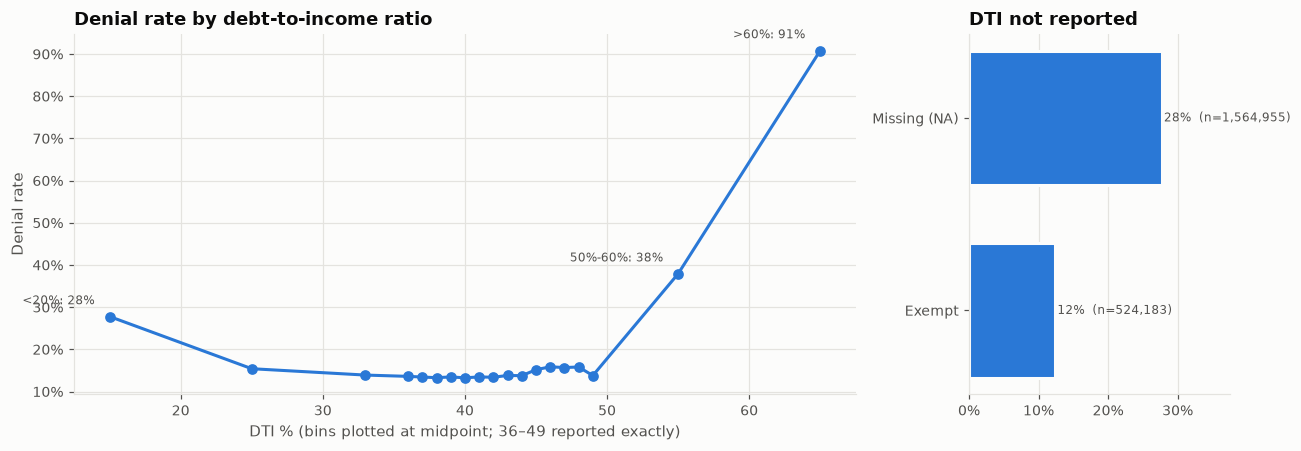

In [7]:
dti = rate_by("debt_to_income_ratio")
dti["dti"] = dti["value"].map(DTI_MAP)
known = dti.dropna(subset=["dti"]).sort_values("dti")
unknown = dti[dti["dti"].isna()].assign(value=lambda d: d["value"].fillna("Missing (NA)"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [3, 1]})
ax1.plot(known["dti"], known["denial_rate"], marker="o", color=hp.BLUE)
ax1.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax1.set(title="Denial rate by debt-to-income ratio",
        xlabel="DTI % (bins plotted at midpoint; 36–49 reported exactly)", ylabel="Denial rate")
for _, r in known.iloc[[0, -2, -1]].iterrows():
    ax1.annotate(f"{r.value}: {r.denial_rate:.0%}", (r.dti, r.denial_rate), textcoords="offset points",
                 xytext=(-10, 8), fontsize=8, color=hp.TEXT_SECONDARY, ha="right")
hp.rate_barh(ax2, unknown["value"].tolist(), unknown["denial_rate"].tolist(), unknown["n"].tolist(),
             title="DTI not reported", xlabel="")
fig.tight_layout(); plt.show()

DTI is the clearest single signal: denial rates are flat (~13–16%) up to the mid-40s, rise in the
upper 40s, reach ~38% at 50–60%, and **jump to ~91% above 60%**. It's reported as a mix of bins and
exact values, so `hmda.features` maps it to a number (`DTI_MAP`). The `<20%` bin is denied *more*
than 20–36%, probably because very low DTI goes with very low or missing income.

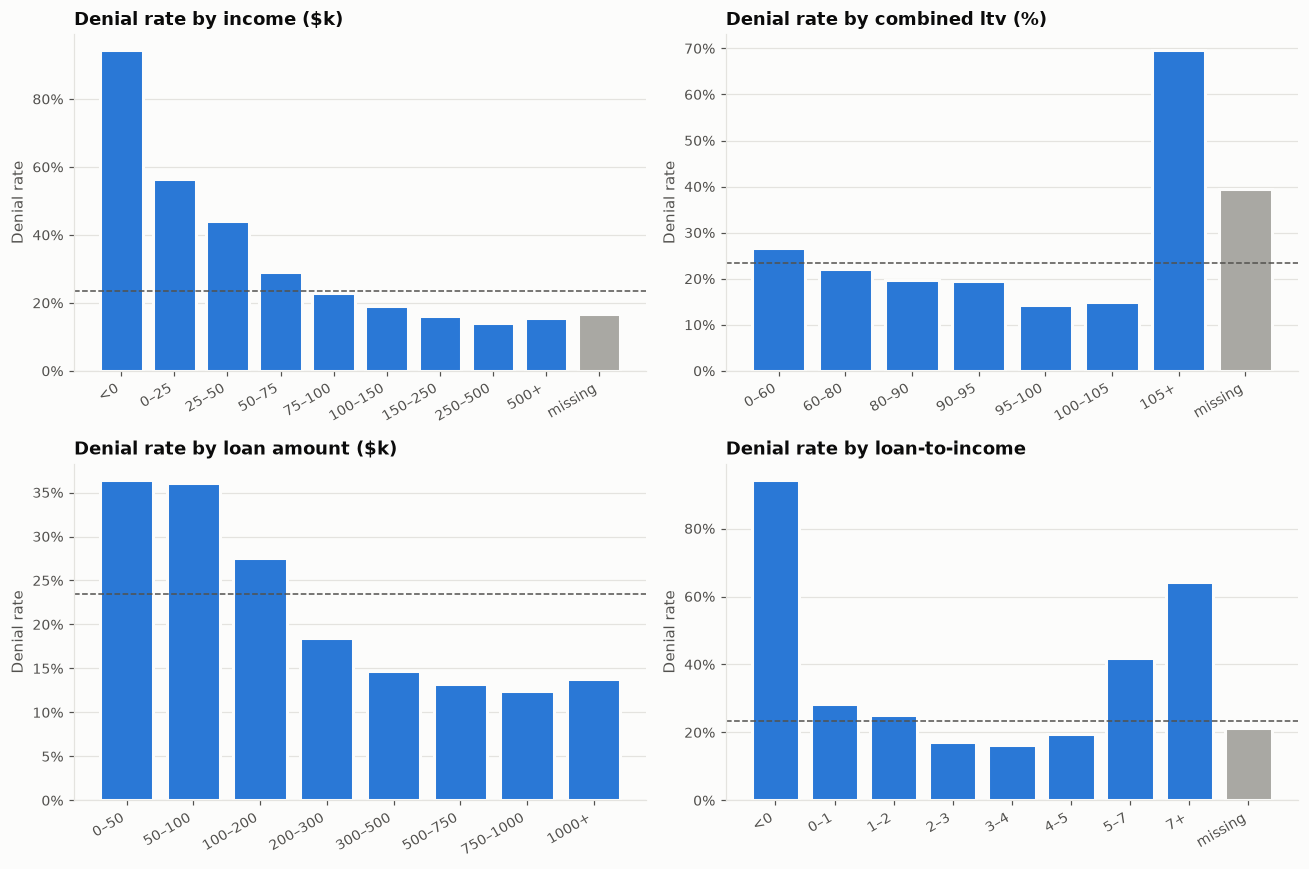

In [8]:
num_bins = {
    "Income ($k)": ("TRY_CAST(income AS DOUBLE)", [0, 25, 50, 75, 100, 150, 250, 500]),
    "Combined LTV (%)": ("TRY_CAST(combined_loan_to_value_ratio AS DOUBLE)", [0, 60, 80, 90, 95, 100, 105]),
    "Loan amount ($k)": ("TRY_CAST(loan_amount AS DOUBLE) / 1000", [0, 50, 100, 200, 300, 500, 750, 1000]),
    "Loan-to-income": ("TRY_CAST(loan_amount AS DOUBLE) / nullif(TRY_CAST(income AS DOUBLE) * 1000, 0)",
                       [0, 1, 2, 3, 4, 5, 7]),
}

def binned(expr, edges):
    # sortable "NN|label" keys: below-range first, then each bin, then top bin, then missing
    case = " ".join(f"WHEN {expr} < {hi} THEN '{i + 1:02d}|{lo}–{hi}'"
                    for i, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])))
    case = (f"CASE WHEN {expr} IS NULL THEN '99|missing' WHEN {expr} < {edges[0]} THEN '00|<{edges[0]}' "
            f"{case} ELSE '{len(edges):02d}|{edges[-1]}+' END")
    d = rate_by(case).sort_values("value")
    d["label"] = d["value"].str.split("|").str[1]
    return d

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (title, (expr, edges)) in zip(axes.flat, num_bins.items()):
    d = binned(expr, edges)
    colors = [hp.MUTED if l == "missing" else hp.BLUE for l in d["label"]]
    ax.bar(range(len(d)), d["denial_rate"], color=colors, edgecolor=hp.SURFACE, linewidth=2, width=0.8)
    ax.set_xticks(range(len(d)), d["label"], rotation=30, ha="right")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(axis="x", visible=False)
    ax.axhline(OVERALL, color=hp.TEXT_SECONDARY, lw=1, ls="--")
    ax.set(title=f"Denial rate by {title.lower()}", ylabel="Denial rate")
fig.tight_layout(); plt.show()

* **Income:** denial falls steadily with income, from 56% under $25k to ~13–15% above $250k.
  Zero/negative reported income is denied ~94% of the time.
* **CLTV:** U-shaped. Low CLTV (<60%, mostly HELOCs and cash-out) is denied 26%, versus 14–15% at
  95–105%, and **above 105% it jumps to ~69%**. Missing CLTV is denied 39%.
* **Loan amount:** small loans (<$100k, often home improvement or HELOC) are denied ~36%.
* **Loan-to-income** is U-shaped too: lowest at 2–4x (~16%), then 41% at 5–7x and 64% above 7x.
* Missing values (gray) carry signal by themselves, so the linear pipeline adds missing-indicator
  columns and the tree models get the NaNs directly.

## 5. Credit & underwriting

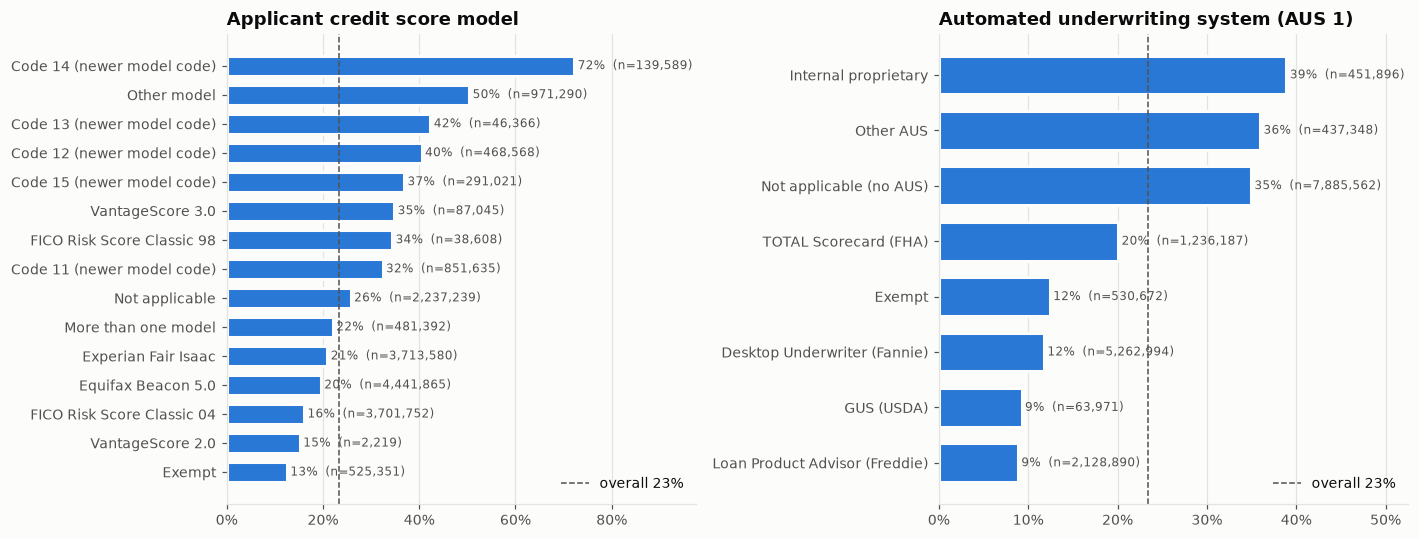

In [9]:
# Codes 1-9 and 1111 per the FFIEC LAR data dictionary. Codes 11-15 are newer scoring-model
# codes; check the current data dictionary for their exact names before quoting them.
score_map = {"1": "Equifax Beacon 5.0", "2": "Experian Fair Isaac", "3": "FICO Risk Score Classic 04",
             "4": "FICO Risk Score Classic 98", "5": "VantageScore 2.0", "6": "VantageScore 3.0",
             "7": "More than one model", "8": "Other model", "9": "Not applicable", "1111": "Exempt",
             **{str(c): f"Code {c} (newer model code)" for c in range(11, 16)}}
aus_map = {"1": "Desktop Underwriter (Fannie)", "2": "Loan Product Advisor (Freddie)",
           "3": "TOTAL Scorecard (FHA)", "4": "GUS (USDA)", "5": "Other AUS",
           "6": "Not applicable (no AUS)", "7": "Internal proprietary", "1111": "Exempt"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
d = rate_by("applicant_credit_score_type", min_n=1000).sort_values("denial_rate", ascending=False)
hp.rate_barh(ax1, d["value"].map(score_map).fillna(d["value"]).tolist(), d["denial_rate"].tolist(),
             d["n"].tolist(), overall=OVERALL, title="Applicant credit score model", xlabel="")
d = rate_by("aus_1", min_n=1000).sort_values("denial_rate", ascending=False)
hp.rate_barh(ax2, d["value"].map(aus_map).fillna(d["value"]).tolist(), d["denial_rate"].tolist(),
             d["n"].tolist(), overall=OVERALL, title="Automated underwriting system (AUS 1)", xlabel="")
fig.tight_layout(); plt.show()

HMDA doesn't publish credit scores, only *which* scoring model the lender used. That still carries
signal because it reflects the lender and product. "Other model" is denied ~50% and several of the
newer codes (11–15) are denied 32–72%, while the classic FICO/Equifax/Experian models are denied
16–21%. For underwriting, applications run through Fannie's or Freddie's AUS are denied 9–12%, while those
with **no AUS** (35%, the largest group at 7.9M) or a lender's **internal** system (39%) are denied much
more. Codes 11–15 aren't labeled here; look them up in the FFIEC data dictionary before quoting them.

## 6. Lenders

5,015 lenders; 2,053 with >= 500 decided applications (97% of volume)
volume-weighted lender denial rate quantiles (10/25/50/75/90%): [0.047 0.104 0.192 0.337 0.464]


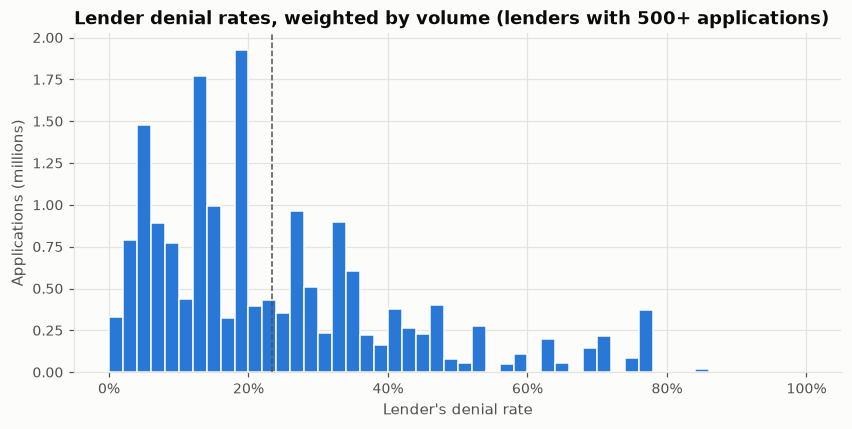

In [10]:
lenders = con.sql("""
    SELECT lei, count(*) AS n, avg(denied) AS denial_rate FROM apps GROUP BY 1
""").df()
big = lenders[lenders["n"] >= 500]
print(f"{len(lenders):,} lenders; {len(big):,} with >= 500 decided applications "
      f"({big['n'].sum() / lenders['n'].sum():.0%} of volume)")
w = np.repeat(big["denial_rate"].to_numpy(), (big["n"] // 100).astype(int))
print("volume-weighted lender denial rate quantiles (10/25/50/75/90%):",
      np.round(np.quantile(w, [.1, .25, .5, .75, .9]), 3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(big["denial_rate"], bins=50, weights=big["n"] / 1e6, color=hp.BLUE, edgecolor=hp.SURFACE, linewidth=1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.axvline(OVERALL, color=hp.TEXT_SECONDARY, lw=1, ls="--")
ax.set(title="Lender denial rates, weighted by volume (lenders with 500+ applications)",
       xlabel="Lender's denial rate", ylabel="Applications (millions)")
plt.show()

Which lender you apply to matters a lot. By volume, the 10th–90th percentile of lender denial rates
runs from **5% to 46%**, and some sizable lenders deny over 75%.
Some lenders mostly take pre-screened, conforming applications, while others (subprime, HELOC-heavy,
online) deny most applicants. With ~5k lenders, one-hot encoding `lei` would be impractical, so the
pipeline **target-encodes** it (cross-fitted, so a row never sees its own label) and adds lender
volume (`lei_volume`).

## 7. Missingness & leakage

In [11]:
cols = [c for c in con.sql("DESCRIBE apps").df()["column_name"] if c not in ("denied", "split_key")]
exprs = ", ".join(
    f"avg(CASE WHEN \"{c}\" IS NULL OR \"{c}\" = 'Exempt' THEN 1.0 ELSE 0 END) "
    f"FILTER (WHERE denied = 0) AS \"{c}|approved\", "
    f"avg(CASE WHEN \"{c}\" IS NULL OR \"{c}\" = 'Exempt' THEN 1.0 ELSE 0 END) "
    f"FILTER (WHERE denied = 1) AS \"{c}|denied\""
    for c in cols)
row = con.sql(f"SELECT {exprs} FROM apps").df().T[0]
row.index = pd.MultiIndex.from_tuples([tuple(i.split("|")) for i in row.index])
miss = (row.astype(float).unstack() * 100).round(1)
miss["gap"] = miss["denied"] - miss["approved"]
miss["group"] = np.where(miss.index.isin(LEAKAGE_COLS), "leakage (dropped)",
                np.where(miss.index.isin(PROTECTED_COLS), "protected (dropped)", "candidate feature"))
print("% missing or 'Exempt', approved vs denied. Largest gaps:")
display(miss.reindex(miss["gap"].abs().sort_values(ascending=False).index).head(20))

% missing or 'Exempt', approved vs denied. Largest gaps:


,approved,denied,gap,group
interest_rate,3.600,100.000,96.400,leakage (dropped)
rate_spread,12.800,100.000,87.200,leakage (dropped)
origination_charges,33.200,100.000,66.800,leakage (dropped)
total_loan_costs,34.100,100.000,65.900,leakage (dropped)
discount_points,65.500,100.000,34.500,leakage (dropped)
lender_credits,78.100,100.000,21.900,leakage (dropped)
denial_reason_2,100.000,78.100,-21.900,leakage (dropped)
co_applicant_age_above_62,56.700,68.400,11.700,protected (dropped)
combined_loan_to_value_ratio,8.500,18.200,9.700,candidate feature
intro_rate_period,79.500,70.900,-8.600,candidate feature


The fields at the top of that table only exist for loans that were **originated**: interest rate,
rate spread, loan costs, points, and lender credits. They're missing for ~100% of denials, so a model
could predict "denied" from missingness alone and get near-perfect scores that are useless in practice.

Some coded fields leak the same way through a "not applicable" code instead of nulls:

In [12]:
leaky_codes = {
    "purchaser_type": "purchaser_type = '0'",                       # 0 = not sold / not originated
    "hoepa_status": "hoepa_status = '3'",                           # 3 = not applicable
    "initially_payable_to_institution": "initially_payable_to_institution = '3'",
    "preapproval": "preapproval = '1'",                             # denied preapprovals are action 7, excluded
    "denial_reason_1": "denial_reason_1 <> '10'",                   # 10 = not applicable
}
rows = []
for col, cond in leaky_codes.items():
    r = con.sql(f"""SELECT avg(({cond})::INT) FILTER (WHERE denied=0),
                       avg(({cond})::INT) FILTER (WHERE denied=1),
                       avg(denied) FILTER (WHERE {cond}), avg(denied) FILTER (WHERE NOT ({cond}))
                FROM apps""").fetchall()[0]
    rows.append({"column": col, "condition": cond, "share_of_approved": r[0], "share_of_denied": r[1],
                 "denial_rate_if_true": r[2], "denial_rate_if_false": r[3]})
pd.DataFrame(rows).set_index("column")

,condition,share_of_approved,share_of_denied,denial_rate_if_true,denial_rate_if_false
column,,,,,
purchaser_type,purchaser_type = '0',0.432,1.000,0.415,0.000
hoepa_status,hoepa_status = '3',0.170,1.000,0.643,0.000
initially_payable_to_institution,initially_payable_to_institution = '3',0.002,0.096,0.931,0.217
preapproval,preapproval = '1',0.029,0.000,0.000,0.239
denial_reason_1,denial_reason_1 <> '10',0.028,1.000,0.917,0.000


All of these are in `hmda.features.LEAKAGE_COLS` and are never given to a model.
`HMDAFeatures` only reads the allow-listed `RAW_INPUT_COLS`, so a new leaky column can't
slip in by accident.

Remaining missingness that *does* differ by outcome (CLTV, property value, loan term) reflects
real application quality (incomplete files get denied), so it's kept as signal.

## 8. Protected attributes (descriptive only)

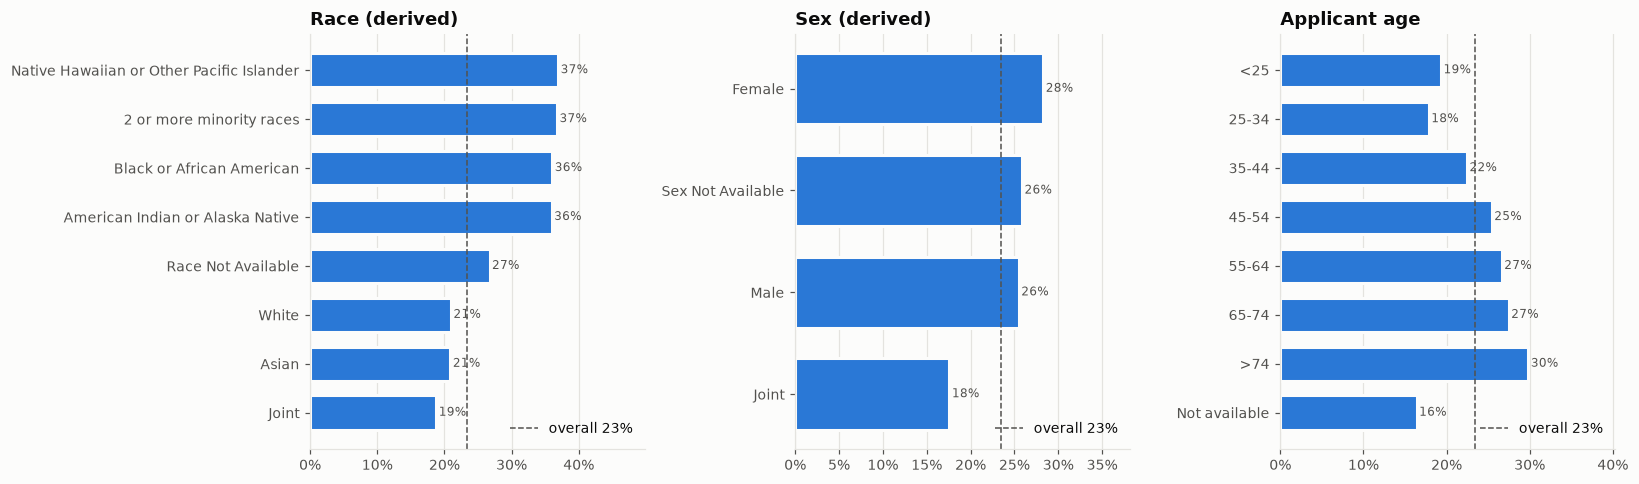

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (col, title) in zip(axes, [("derived_race", "Race (derived)"),
                                   ("derived_sex", "Sex (derived)"),
                                   ("applicant_age", "Applicant age")]):
    d = rate_by(col, min_n=20000)
    if col == "applicant_age":
        order = ["<25", "25-34", "35-44", "45-54", "55-64", "65-74", ">74", "8888"]
        d = d.set_index("value").loc[order].reset_index().replace({"value": {"8888": "Not available"}})
    else:
        d = d.sort_values("denial_rate", ascending=False)
    hp.rate_barh(ax, d["value"].tolist(), d["denial_rate"].tolist(), overall=OVERALL, title=title, xlabel="")
fig.tight_layout(); plt.show()

Denial rates differ widely by race: Black, American Indian, Pacific Islander, and multi-race applicants
are denied ~36–37% of the time vs ~21% for white and Asian applicants (about 1.7x). Denials also rise with
age (18% at 25–34 to 30% over 74), and women are denied slightly more than men (28% vs 26%). These raw gaps mix together differences in income, DTI,
product, and lender, so on their own they don't measure discrimination.

**Modeling choice:** race, ethnicity, sex, and age (`PROTECTED_COLS`) are **excluded from model
inputs** by default. ECOA prohibits using them in credit decisions. We keep them only to **audit**
model errors by group (see the modeling notebook). Geography and tract minority % can still act as
proxies, which the audit should check.

## 9. Feature importance

Fit the default LightGBM pipeline on a **3% sample of 2024** (~260k decided applications) and
evaluate on a **1% sample of 2025**. Three views:

1. **Permutation importance on raw input columns:** how much test AUC drops when one raw HMDA
   column is shuffled. It accounts for every engineered feature built from that column.
2. **Mean |SHAP|** on the engineered features (LightGBM's built-in `pred_contrib`).
3. **Split gain** from LightGBM, which is fast but biased toward high-cardinality features.

In [14]:
from lightgbm import LGBMClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

cols = HMDAFeatures().input_cols()
train = approved_vs_denied(load_hmda(years=[2024], actions=[1, 2, 3], columns=cols, sample=0.03))
test = approved_vs_denied(load_hmda(years=[2025], actions=[1, 2, 3], columns=cols, sample=0.01))
X_tr, y_tr = split_xy(train)
X_te, y_te = split_xy(test)
print(f"train {len(X_tr):,} rows (2024), test {len(X_te):,} rows (2025), {X_tr.shape[1]} raw input columns")

lgbm = make_pipeline(LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63,
                                    min_child_samples=100, subsample=0.8, subsample_freq=1,
                                    colsample_bytree=0.8, verbose=-1, random_state=0), kind="tree")
lgbm.fit(X_tr, y_tr)
p_te = lgbm.predict_proba(X_te)[:, 1]
print(f"test ROC-AUC: {roc_auc_score(y_te, p_te):.4f}")

train 259,480 rows (2024), test 94,006 rows (2025), 42 raw input columns


test ROC-AUC: 0.8982


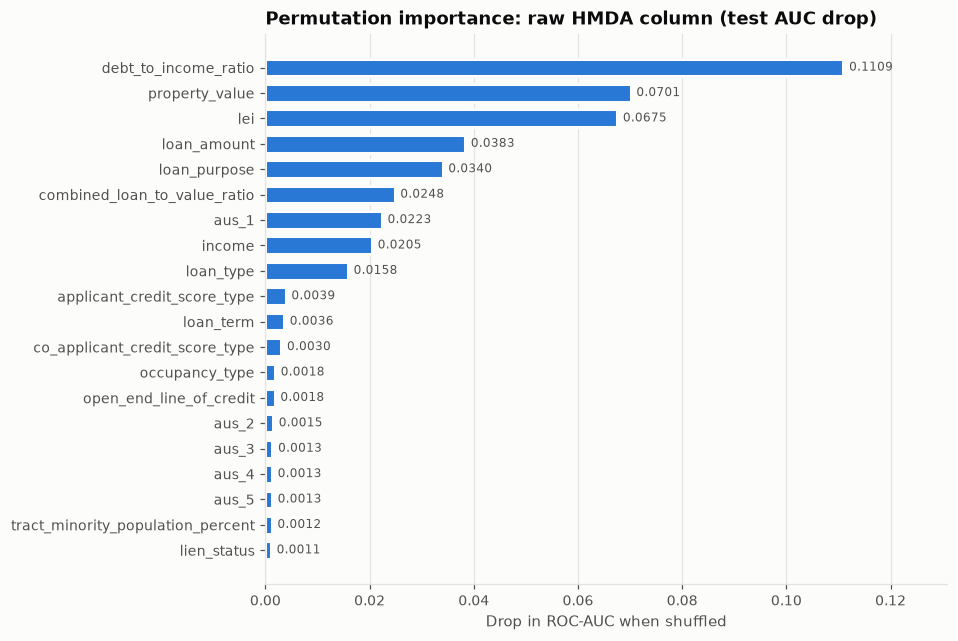

In [15]:
sub = X_te.sample(40_000, random_state=0)
perm = permutation_importance(lgbm, sub, y_te[X_te.index.get_indexer(sub.index)],
                              scoring="roc_auc", n_repeats=3, random_state=0, n_jobs=1)
perm_imp = (pd.DataFrame({"auc_drop": perm.importances_mean, "std": perm.importances_std},
                         index=sub.columns).sort_values("auc_drop", ascending=False))

top = perm_imp.head(20)
fig, ax = plt.subplots(figsize=(8, 6.5))
hp.importance_barh(ax, top.index.tolist(), top["auc_drop"].tolist(),
                   title="Permutation importance: raw HMDA column (test AUC drop)",
                   xlabel="Drop in ROC-AUC when shuffled", fmt="{:.4f}")
plt.show()

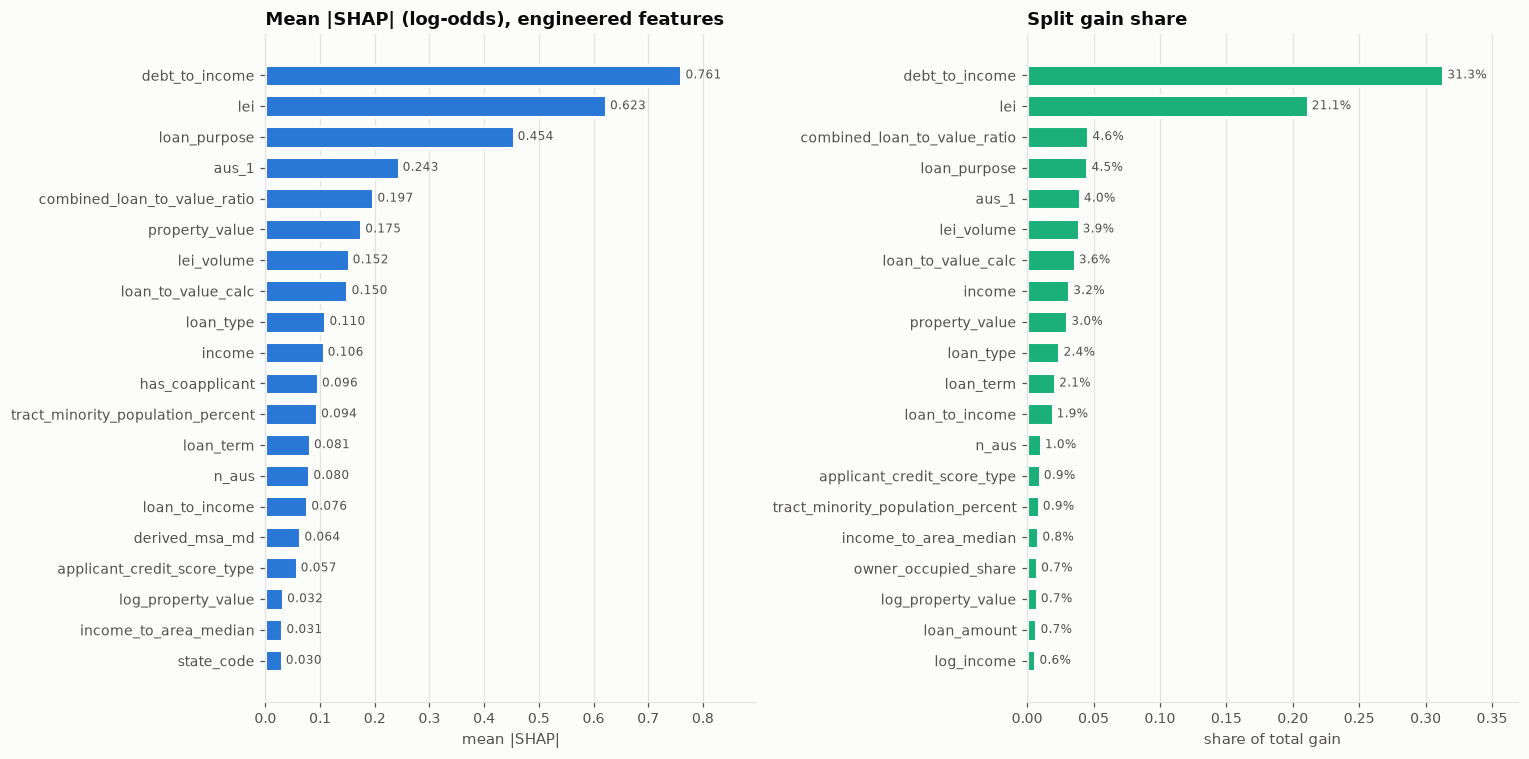

In [16]:
model = lgbm.named_steps["model"]
Xt = lgbm[:-1].transform(sub)
contrib = model.predict(Xt, pred_contrib=True)[:, :-1]      # last column is the bias term
imp = pd.DataFrame({
    "mean_abs_shap": np.abs(contrib).mean(axis=0),
    "gain_share": model.booster_.feature_importance("gain") / model.booster_.feature_importance("gain").sum(),
}, index=Xt.columns).sort_values("mean_abs_shap", ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
t = imp.head(20)
hp.importance_barh(ax1, t.index.tolist(), t["mean_abs_shap"].tolist(),
                   title="Mean |SHAP| (log-odds), engineered features", xlabel="mean |SHAP|")
t = imp.sort_values("gain_share", ascending=False).head(20)
hp.importance_barh(ax2, t.index.tolist(), t["gain_share"].tolist(), color=hp.AQUA,
                   title="Split gain share", xlabel="share of total gain", fmt="{:.1%}")
fig.tight_layout(); plt.show()

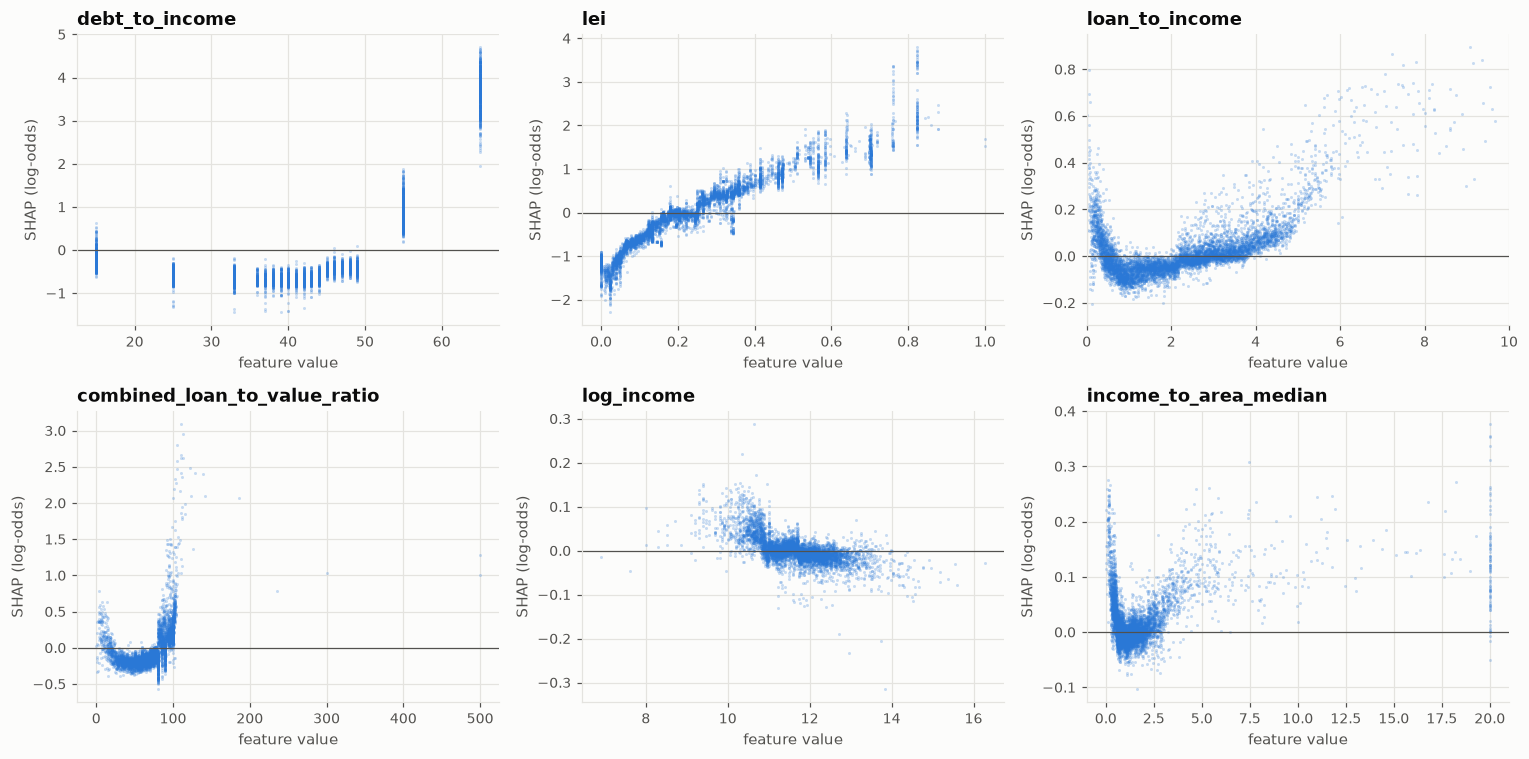

In [17]:
# How each top feature pushes the prediction: SHAP value vs feature value (sampled points)
show = ["debt_to_income", "lei", "loan_to_income", "combined_loan_to_value_ratio", "log_income", "income_to_area_median"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
idx = np.random.default_rng(0).choice(len(Xt), 8000, replace=False)
for ax, f in zip(axes.flat, show):
    j = Xt.columns.get_loc(f)
    ax.scatter(Xt.iloc[idx, j], contrib[idx, j], s=4, alpha=0.25, color=hp.BLUE, linewidths=0)
    ax.axhline(0, color=hp.TEXT_SECONDARY, lw=0.8)
    ax.set(title=f, xlabel="feature value", ylabel="SHAP (log-odds)")
    if f in ("loan_to_income",):
        ax.set_xlim(0, 10)
fig.tight_layout(); plt.show()

## 10. Takeaways

**Scale and target**
* 22.5M applications nationwide (2024–2025); **18.0M decided**, of which **23.4% were denied**. The denial
  rate fell from 24.3% (2024) to 22.6% (2025), and it fell in every state. That shift is why the models
  train on 2024 and test on 2025.

**Strongest signals** (permutation importance, test-AUC drop when the raw column is shuffled)
1. **Debt-to-income** (0.111): flat ~13–16% denial up to DTI 49, then 38% at 50–60% and **91% above 60%**.
2. **Property value / LTV** (property value 0.070, CLTV 0.025): U-shaped. CLTV above 105% is denied ~69%.
3. **Lender (`lei`)** (0.068; #2 by mean |SHAP|): the volume-weighted 10th–90th percentile of lender
   denial rates runs from 5% to 46%. Who you apply to matters nearly as much as your finances.
4. **Loan size and purpose** (loan amount 0.038, purpose 0.034): home purchase loans are denied 14%;
   home improvement, cash-out, and "other" purpose loans 31–40%. Manufactured homes are denied 53%.
5. **Underwriting and credit-model codes** (AUS 0.022): Fannie/Freddie AUS ~9–12% denial; no AUS or a
   proprietary system 35–39%.
6. **Income** (0.021): 56% denial under $25k, ~13–15% above $250k; zero/negative income ~94%.

State on its own adds little once financials and lender are known (mean |SHAP| 0.03).

**Leakage.** Interest rate, rate spread, loan costs, points, lender credits, denial reasons, purchaser type,
HOEPA status, preapproval, and initially-payable are all recorded *after* the decision. They're missing or
coded "not applicable" for ~100% of denials. They're listed in `LEAKAGE_COLS` and never used. A model given
only these fields reaches **0.994 AUC** (notebook 02), which shows how badly they would inflate results.

**Fairness context.** Raw denial rates are ~36–37% for Black, American Indian, Pacific Islander, and
multi-race applicants vs ~21% for white and Asian applicants. Race, ethnicity, sex, and age are kept
out of the model and used only to audit it. `tract_minority_population_percent` still carries some
signal (mean |SHAP| 0.094), so geography is a potential proxy that the audit in notebook 03 checks.

**Baseline.** A default LightGBM on a 3% sample reaches **0.898 ROC-AUC** on 2025, a starting point
for model selection.